# TelcoPeople — Diagnostic de l’instabilité temporelle

Le modèle avec clustering obtient un F1 nettement plus faible en juin 2023 qu’en décembre 2023 et juin 2024.

Ce notebook cherche à déterminer si cette baisse provient :

1. d’un changement de distribution des variables ;
2. d’un changement dans les relations entre variables et départ ;
3. d’un problème de calibration des probabilités ;
4. d’un seuil global mal adapté à cette période ;
5. d’un volume d’apprentissage encore insuffisant.

L’objectif n’est pas d’ajouter immédiatement un nouveau modèle, mais d’expliquer précisément l’instabilité observée.

## 1. Bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid")

## 2. Chargement des données et des prédictions hors temps

Le fichier `predictions_hors_temps_clustering.csv` a été produit par le notebook 08.

In [2]:
CHEMIN_DATA = "../data/raw/"
CHEMIN_REPORTS = "../reports/"

train = pd.read_csv(CHEMIN_DATA + "telcopeople_train.csv")
predictions = pd.read_csv(
    CHEMIN_REPORTS + "predictions_hors_temps_clustering.csv",
    parse_dates=["periode"]
)

train["date_reference"] = pd.to_datetime(
    train["date_reference"], format="mixed", dayfirst=True
)

print("Train :", train.shape)
print("Prédictions hors temps :", predictions.shape)
print(predictions["periode"].value_counts().sort_index())

Train : (5444, 42)
Prédictions hors temps : (3586, 5)
periode
2023-06-30    1083
2023-12-31    1189
2024-06-30    1314
Name: count, dtype: int64


## 3. Nettoyage minimal pour le diagnostic

In [3]:
def preparer_diagnostic(df):
    df = df.copy()

    df["departement"] = (
        df["departement"].fillna("INCONNU").str.strip().str.upper()
        .str.replace("DEPT", "DEP", regex=False)
    )
    df["contrat"] = (
        df["contrat"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(".", "", regex=False)
    )
    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()

    for col in ["poste", "grade", "code_site", "source_sirh", "genre", "niveau_etude"]:
        df[col] = df[col].fillna("INCONNU").astype(str).str.strip().str.upper()

    for col in ["date_naissance", "date_embauche", "date_derniere_promotion", "date_derniere_absence"]:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

    df["salaire_mensuel_num"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
        errors="coerce"
    )

    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["ratio_salaire_reference"] = (
        df["salaire_mensuel_num"] / df["reference_salaire_grade"]
    )
    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)

    return df.replace([np.inf, -np.inf], np.nan)

train_diag = preparer_diagnostic(train)

## 4. Résultats par période au seuil global

Cette cellule reproduit les performances du notebook 08 avec le seuil global de 0,59.

In [4]:
SEUIL_GLOBAL = 0.59

resultats = []
for periode, groupe in predictions.groupby("periode"):
    pred = (groupe["proba_clustering"] >= SEUIL_GLOBAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(groupe["target"], pred).ravel()

    resultats.append({
        "periode": periode,
        "effectif": len(groupe),
        "departs": int(groupe["target"].sum()),
        "positifs_predits": int(pred.sum()),
        "vrais_positifs": int(tp),
        "faux_positifs": int(fp),
        "faux_negatifs": int(fn),
        "f1": f1_score(groupe["target"], pred),
        "precision": precision_score(groupe["target"], pred, zero_division=0),
        "rappel": recall_score(groupe["target"], pred, zero_division=0),
        "auc": roc_auc_score(groupe["target"], groupe["proba_clustering"])
    })

resultats = pd.DataFrame(resultats)
display(resultats)

,periode,effectif,departs,positifs_predits,vrais_positifs,faux_positifs,faux_negatifs,f1,precision,rappel,auc
0,2023-06-30,1083,106,115,23,92,83,0.208145,0.200000,0.216981,0.668295
1,2023-12-31,1189,130,166,49,117,81,0.331081,0.295181,0.376923,0.718036
2,2024-06-30,1314,129,242,60,182,69,0.323450,0.247934,0.465116,0.715841


## 5. Le problème vient-il du classement ou du seuil ?

L’AUC mesure le classement indépendamment du seuil. Le meilleur F1 local mesure ce que chaque période pourrait atteindre avec son propre seuil.

In [5]:
comparaison_seuils = []

for periode, groupe in predictions.groupby("periode"):
    lignes = []
    for seuil in np.arange(0.20, 0.81, 0.01):
        pred = (groupe["proba_clustering"] >= seuil).astype(int)
        lignes.append({
            "seuil": round(float(seuil), 2),
            "f1": f1_score(groupe["target"], pred),
            "precision": precision_score(groupe["target"], pred, zero_division=0),
            "rappel": recall_score(groupe["target"], pred, zero_division=0)
        })

    lignes = pd.DataFrame(lignes)
    meilleur = lignes.loc[lignes["f1"].idxmax()]

    comparaison_seuils.append({
        "periode": periode,
        "auc": roc_auc_score(groupe["target"], groupe["proba_clustering"]),
        "seuil_global": SEUIL_GLOBAL,
        "f1_seuil_global": f1_score(
            groupe["target"], groupe["proba_clustering"] >= SEUIL_GLOBAL
        ),
        "meilleur_seuil_local": meilleur["seuil"],
        "meilleur_f1_local": meilleur["f1"],
        "gain_seuil_local": meilleur["f1"] - f1_score(
            groupe["target"], groupe["proba_clustering"] >= SEUIL_GLOBAL
        )
    })

comparaison_seuils = pd.DataFrame(comparaison_seuils)
display(comparaison_seuils)

,periode,auc,seuil_global,f1_seuil_global,meilleur_seuil_local,meilleur_f1_local,gain_seuil_local
0,2023-06-30,0.668295,0.59,0.208145,0.45,0.253165,0.045020
1,2023-12-31,0.718036,0.59,0.331081,0.60,0.338028,0.006947
2,2024-06-30,0.715841,0.59,0.323450,0.59,0.323450,0.000000


## 6. Distribution des probabilités

Cette visualisation compare les probabilités des départs et non-départs pour chaque période.

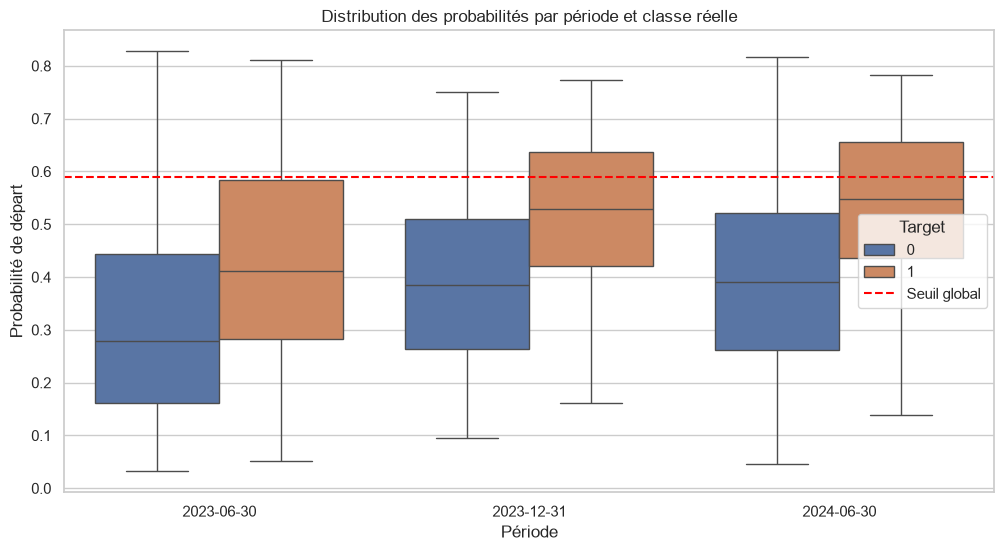

In [6]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=predictions,
    x="periode",
    y="proba_clustering",
    hue="target"
)
plt.axhline(SEUIL_GLOBAL, color="red", linestyle="--", label="Seuil global")
plt.title("Distribution des probabilités par période et classe réelle")
plt.xlabel("Période")
plt.ylabel("Probabilité de départ")
plt.legend(title="Target")
plt.show()

## 7. Calibration des probabilités

Un modèle peut bien classer les observations tout en produisant des probabilités trop hautes ou trop basses selon la période.

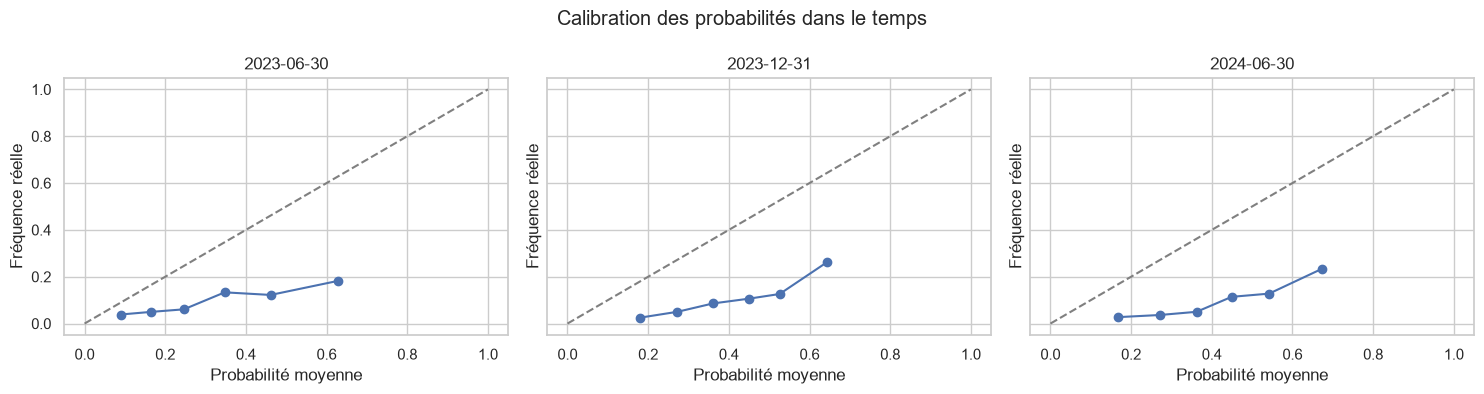

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for axe, (periode, groupe) in zip(axes, predictions.groupby("periode")):
    fraction_positive, moyenne_predite = calibration_curve(
        groupe["target"],
        groupe["proba_clustering"],
        n_bins=6,
        strategy="quantile"
    )
    axe.plot(moyenne_predite, fraction_positive, marker="o")
    axe.plot([0, 1], [0, 1], linestyle="--", color="gray")
    axe.set_title(str(periode.date()))
    axe.set_xlabel("Probabilité moyenne")
    axe.set_ylabel("Fréquence réelle")

plt.suptitle("Calibration des probabilités dans le temps")
plt.tight_layout()
plt.show()

## 8. Évolution des variables numériques

Le test de Kolmogorov-Smirnov compare juin 2023 aux deux périodes suivantes. Une grande statistique KS signale une différence de distribution.

In [8]:
variables_numeriques = [
    "engagement_actuel", "engagement_precedent", "engagement_moyen",
    "performance_actuelle", "performance_precedente", "performance_moyenne",
    "salaire_mensuel_num", "ratio_salaire_reference",
    "age", "anciennete", "jours_abs_6m", "nb_abs_6m",
    "abs_non_just_6m", "taille_departement"
]

reference = train_diag.loc[
    train_diag["date_reference"] == pd.Timestamp("2023-06-30")
]

lignes_drift = []
for periode in [pd.Timestamp("2023-12-31"), pd.Timestamp("2024-06-30")]:
    comparaison = train_diag.loc[train_diag["date_reference"] == periode]

    for variable in variables_numeriques:
        a = reference[variable].dropna()
        b = comparaison[variable].dropna()
        if len(a) and len(b):
            test_ks = ks_2samp(a, b)
            lignes_drift.append({
                "periode_comparee": periode,
                "variable": variable,
                "ks": test_ks.statistic,
                "p_value": test_ks.pvalue,
                "moyenne_juin_2023": a.mean(),
                "moyenne_periode_comparee": b.mean()
            })

resultats_drift_numerique = pd.DataFrame(lignes_drift)
display(
    resultats_drift_numerique.sort_values("ks", ascending=False).head(25)
)

,periode_comparee,variable,ks,p_value,moyenne_juin_2023,moyenne_periode_comparee
27,2024-06-30,taille_departement,0.396984,4.219618e-84,177.906741,219.045662
13,2023-12-31,taille_departement,0.388815,5.718228e-77,177.906741,194.978133
9,2023-12-31,anciennete,0.218683,3.100930e-24,2.300652,2.555656
23,2024-06-30,anciennete,0.084361,3.946440e-04,2.300652,2.435256
8,2023-12-31,age,0.057254,4.621255e-02,36.045530,36.651007
1,2023-12-31,engagement_precedent,0.039625,5.745362e-01,3.602620,3.622624
10,2023-12-31,jours_abs_6m,0.036368,4.279566e-01,1.532779,1.746005
15,2024-06-30,engagement_precedent,0.034957,7.005427e-01,3.602620,3.617918
3,2023-12-31,performance_actuelle,0.031313,6.948012e-01,3.462563,3.438619
22,2024-06-30,age,0.031228,5.941113e-01,36.045530,36.222337


## 9. Évolution des variables catégorielles

La distance de variation totale mesure la différence de répartition des catégories entre périodes.

In [9]:
variables_categorielles = [
    "departement", "poste", "contrat", "grade",
    "ville_affectation", "code_site", "source_sirh"
]

lignes_drift_cat = []
for periode in [pd.Timestamp("2023-12-31"), pd.Timestamp("2024-06-30")]:
    comparaison = train_diag.loc[train_diag["date_reference"] == periode]

    for variable in variables_categorielles:
        p = reference[variable].value_counts(normalize=True)
        q = comparaison[variable].value_counts(normalize=True)
        index = p.index.union(q.index)
        tvd = 0.5 * (
            p.reindex(index, fill_value=0) - q.reindex(index, fill_value=0)
        ).abs().sum()

        lignes_drift_cat.append({
            "periode_comparee": periode,
            "variable": variable,
            "distance_variation_totale": tvd
        })

resultats_drift_categoriel = pd.DataFrame(lignes_drift_cat)
display(
    resultats_drift_categoriel.sort_values(
        "distance_variation_totale", ascending=False
    )
)

,periode_comparee,variable,distance_variation_totale
8,2024-06-30,poste,0.043790
1,2023-12-31,poste,0.037290
7,2024-06-30,departement,0.023409
13,2024-06-30,source_sirh,0.020957
11,2024-06-30,ville_affectation,0.016502
0,2023-12-31,departement,0.015950
12,2024-06-30,code_site,0.015813
6,2023-12-31,source_sirh,0.014775
5,2023-12-31,code_site,0.014064
10,2024-06-30,grade,0.011405


## 10. Les relations avec la cible changent-elles ?

Pour chaque variable numérique, l’AUC univariée absolue est calculée par période. Une forte variation indique que le signal prédictif évolue dans le temps.

In [10]:
relations_temporelles = []

for periode, groupe in train_diag.groupby("date_reference"):
    if periode not in predictions["periode"].unique():
        continue

    for variable in variables_numeriques:
        donnees = groupe[[variable, "target"]].dropna()
        if donnees[variable].nunique() > 1 and donnees["target"].nunique() == 2:
            auc = roc_auc_score(donnees["target"], donnees[variable])
            relations_temporelles.append({
                "periode": periode,
                "variable": variable,
                "auc_univariee_absolue": max(auc, 1 - auc)
            })

relations_temporelles = pd.DataFrame(relations_temporelles)
pivot_relations = relations_temporelles.pivot(
    index="variable", columns="periode", values="auc_univariee_absolue"
)
pivot_relations["amplitude"] = pivot_relations.max(axis=1) - pivot_relations.min(axis=1)

display(pivot_relations.sort_values("amplitude", ascending=False).head(20))

periode,2023-06-30 00:00:00,2023-12-31 00:00:00,2024-06-30 00:00:00,amplitude
variable,,,,
salaire_mensuel_num,0.511867,0.568351,0.594796,0.082929
ratio_salaire_reference,0.614559,0.626643,0.662723,0.048164
taille_departement,0.511795,0.514448,0.559140,0.047346
anciennete,0.550772,0.506156,0.506535,0.044615
performance_moyenne,0.513271,0.502748,0.540050,0.037301
performance_actuelle,0.508995,0.507636,0.538760,0.031125
nb_abs_6m,0.545663,0.568617,0.539090,0.029527
jours_abs_6m,0.540618,0.564938,0.540356,0.024582
performance_precedente,0.533720,0.529632,0.552251,0.022619


## 11. Analyse des faux négatifs de juin 2023

Les faux négatifs sont les départs réels classés sous le seuil global.

In [11]:
pred_2023 = predictions.loc[
    predictions["periode"] == pd.Timestamp("2023-06-30")
].copy()
pred_2023["prediction"] = (
    pred_2023["proba_clustering"] >= SEUIL_GLOBAL
).astype(int)

faux_negatifs_ids = pred_2023.loc[
    (pred_2023["target"] == 1) & (pred_2023["prediction"] == 0),
    "id"
]

faux_negatifs = train_diag.loc[
    train_diag["id"].isin(faux_negatifs_ids)
].copy()

vrais_positifs_ids = pred_2023.loc[
    (pred_2023["target"] == 1) & (pred_2023["prediction"] == 1),
    "id"
]
vrais_positifs = train_diag.loc[
    train_diag["id"].isin(vrais_positifs_ids)
].copy()

comparaison_departs_2023 = pd.DataFrame({
    "faux_negatifs": faux_negatifs[variables_numeriques].mean(),
    "vrais_positifs": vrais_positifs[variables_numeriques].mean()
})
comparaison_departs_2023["ecart"] = (
    comparaison_departs_2023["faux_negatifs"] -
    comparaison_departs_2023["vrais_positifs"]
)

display(comparaison_departs_2023.sort_values("ecart", key=abs, ascending=False))

,faux_negatifs,vrais_positifs,ecart
salaire_mensuel_num,929638.554217,621521.739130,308116.815086
age,36.758945,35.127697,1.631249
taille_departement,172.313253,173.869565,-1.556312
anciennete,2.773014,1.655924,1.117090
engagement_actuel,3.271538,2.532632,0.738907
engagement_moyen,3.278042,2.557343,0.720698
engagement_precedent,3.314602,2.829005,0.485597
ratio_salaire_reference,1.162623,0.831841,0.330782
performance_moyenne,3.543377,3.234500,0.308877
performance_actuelle,3.530000,3.240500,0.289500


## 12. Postes et départements difficiles en juin 2023

Cette cellule repère les groupes contenant beaucoup de faux négatifs.

In [12]:
diagnostic_2023 = train_diag.loc[
    train_diag["date_reference"] == pd.Timestamp("2023-06-30")
].merge(
    pred_2023[["id", "prediction", "proba_clustering"]],
    on="id",
    how="left"
)

diagnostic_2023["faux_negatif"] = (
    (diagnostic_2023["target"] == 1) &
    (diagnostic_2023["prediction"] == 0)
).astype(int)

for variable in ["poste", "departement", "contrat", "grade"]:
    tableau = diagnostic_2023.groupby(variable).agg(
        effectif=("id", "count"),
        departs=("target", "sum"),
        faux_negatifs=("faux_negatif", "sum")
    )
    tableau["taux_faux_negatifs_parmi_departs"] = (
        tableau["faux_negatifs"] / tableau["departs"].replace(0, np.nan)
    )

    print(f"\n--- {variable} ---")
    display(
        tableau.loc[tableau["departs"] >= 3]
        .sort_values("faux_negatifs", ascending=False)
        .head(15)
    )


--- poste ---


,effectif,departs,faux_negatifs,taux_faux_negatifs_parmi_departs
poste,,,,
SUPERVISEUR CENTRE DE CONTACTS,94,8,7,0.875000
CONSEILLER CLIENT,110,10,7,0.700000
CONSEILLER COMMERCIAL,91,10,6,0.600000
INGÉNIEUR RÉSEAU,65,5,5,1.000000
HR BUSINESS PARTNER,16,4,4,1.000000
ANALYSTE CX,36,4,4,1.000000
CHARGÉ GRANDS COMPTES,58,6,4,0.666667
MANAGER SERVICE CLIENT,43,6,4,0.666667
MANAGER TECHNIQUE,27,5,4,0.800000



--- departement ---


,effectif,departs,faux_negatifs,taux_faux_negatifs_parmi_departs
departement,,,,
DEP04,283,28,22,0.785714
DEP02,214,21,15,0.714286
DEP03,204,16,14,0.875000
DEP10,47,10,8,0.800000
DEP07,73,8,7,0.875000
DEP08,82,9,5,0.555556
DEP05,71,4,4,1.000000
DEP06,52,6,4,0.666667
DEP09,45,4,4,1.000000



--- contrat ---


,effectif,departs,faux_negatifs,taux_faux_negatifs_parmi_departs
contrat,,,,
CDI,911,84,67,0.797619
CDD,172,22,16,0.727273



--- grade ---


,effectif,departs,faux_negatifs,taux_faux_negatifs_parmi_departs
grade,,,,
G3,275,26,25,0.961538
G2,336,28,20,0.714286
G4,145,22,16,0.727273
G1,255,22,15,0.681818
G5,72,8,7,0.875000


## 13. Diagnostic automatique

Cette cellule résume si juin 2023 souffre surtout d’un problème de classement, de seuil ou de dérive des données.

In [13]:
ligne_2023 = comparaison_seuils.loc[
    comparaison_seuils["periode"] == pd.Timestamp("2023-06-30")
].iloc[0]

print("AUC juin 2023 :", round(ligne_2023["auc"], 4))
print("F1 au seuil global :", round(ligne_2023["f1_seuil_global"], 4))
print("Meilleur F1 local :", round(ligne_2023["meilleur_f1_local"], 4))
print("Meilleur seuil local :", ligne_2023["meilleur_seuil_local"])
print("Gain possible par simple adaptation du seuil :", round(ligne_2023["gain_seuil_local"], 4))

if ligne_2023["auc"] < 0.68:
    print("Conclusion : le classement est principalement insuffisant en juin 2023.")
elif ligne_2023["gain_seuil_local"] > 0.04:
    print("Conclusion : la calibration ou le seuil explique une part importante de la baisse.")
else:
    print("Conclusion : la baisse semble combiner classement, calibration et dérive temporelle.")

AUC juin 2023 : 0.6683
F1 au seuil global : 0.2081
Meilleur F1 local : 0.2532
Meilleur seuil local : 0.45
Gain possible par simple adaptation du seuil : 0.045
Conclusion : le classement est principalement insuffisant en juin 2023.


## 14. Export du diagnostic

In [14]:
resultats.to_csv("../reports/diagnostic_performance_par_periode.csv", index=False)
comparaison_seuils.to_csv("../reports/diagnostic_seuils_par_periode.csv", index=False)
resultats_drift_numerique.to_csv("../reports/drift_variables_numeriques.csv", index=False)
resultats_drift_categoriel.to_csv("../reports/drift_variables_categorielles.csv", index=False)
pivot_relations.to_csv("../reports/stabilite_relations_variables_cible.csv")
comparaison_departs_2023.to_csv("../reports/comparaison_departs_juin_2023.csv")

print("Exports terminés dans reports.")

Exports terminés dans reports.


## Conclusion

Ce diagnostic doit permettre de décider entre plusieurs réponses possibles :

- conserver un seuil global si la baisse vient du classement ;
- calibrer les probabilités si le classement reste bon mais le seuil dérive ;
- pondérer davantage les périodes récentes si les relations changent ;
- créer des modèles par régime temporel si plusieurs mécanismes distincts apparaissent ;
- accepter une limite de performance si juin 2023 contient peu de signal observable.

Aucune nouvelle complexité ne doit être ajoutée avant d’avoir identifié la cause dominante.